# Chen 2020 (NPC, 10x) — 03 Signatures / Gate 2

Reads `manifold.h5ad`. Renders the three embryonic-module signature UMAPs (Gast, pSom, Crest) and characterizes their **geography** to decide **Gate 2**: does the embryonic pattern appear — a Gast/pSom hub diverging into two arms (branching), or the non-branching case (Gast/pSom overlap with Crest as an inverse/terminal gradient)? Both are GO; a NO-GO is the pattern being *absent*.

All signatures are graph-smoothed (carried from 02). Module->arm assignment is read off the scores, not off subtype names (spec §1).

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm
sc.settings.verbosity = 1; sc.settings.seed = 0
name='Chen2020_Head-and-Neck-3'; cat='Head-and-Neck'
pth=os.path.join('..', '..', '..', '..')
pth_data=os.path.join(pth,'data')
pth_out=os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig=os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)
adata=sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
print('loaded manifold.h5ad:', adata.shape, '| geometry:', adata.uns.get('geometry'))

loaded manifold.h5ad: (3236, 22080) | geometry: non-branching (curve)


### Signature UMAPs — Gast, pSom, Crest (smoothed)
Each saved as its own `{name}_signature.pdf` with a matching colorbar in `colorbars/`, per the deliverable table.

saved Gast_signature.pdf (vmin=-0.055 vmax=0.025)
saved pSom_signature.pdf (vmin=-0.026 vmax=0.035)
saved Crest_signature.pdf (vmin=-0.041 vmax=0.022)


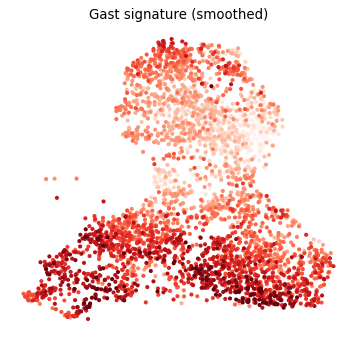

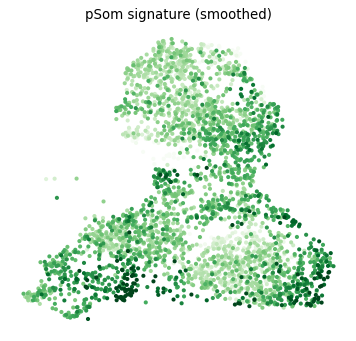

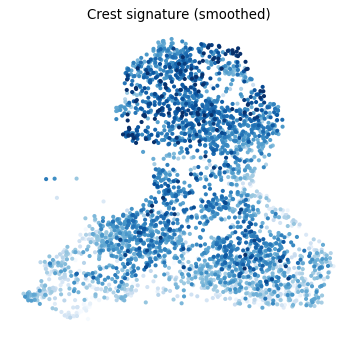

In [1]:
sigs=['Gast','pSom','Crest']; cmaps={'Gast':'Reds','pSom':'Greens','Crest':'Blues'}
for s in sigs:
    v=adata.obs[s+'_sm'].values
    vmin,vmax=np.quantile(v,0.02),np.quantile(v,0.98)
    fig,ax=plt.subplots(figsize=(5.5,5))
    sc.pl.umap(adata,color=s+'_sm',cmap=cmaps[s],vmin=vmin,vmax=vmax,size=55,ax=ax,show=False,frameon=False,colorbar_loc=None,title='%s signature (smoothed)'%s)
    fig.savefig(os.path.join(pth_fig,'%s_signature.pdf'%s),bbox_inches='tight')
    cb,cax=plt.subplots(figsize=(1.0,4))
    import matplotlib as mpl
    mpl.colorbar.ColorbarBase(cax,cmap=cm.get_cmap(cmaps[s]),norm=Normalize(vmin,vmax)); cax.set_title(s,size=10)
    cb.savefig(os.path.join(pth_fig,'colorbars','%s_colorbar.pdf'%s),bbox_inches='tight'); plt.close(cb)
    print('saved %s_signature.pdf (vmin=%.3f vmax=%.3f)'%(s,vmin,vmax))

### Geography — is it a bifurcation or a single graded axis?
Three tests: (1) whole-manifold signature correlations, (2) spatial overlap of the top-quintile cells of each signature (Jaccard) — a hub-then-split would show Gast/pSom co-located, two arms would show them separated, and (3) signature means along the pseudotime axis.

In [1]:
G,P,C=adata.obs.Gast_sm.values,adata.obs.pSom_sm.values,adata.obs.Crest_sm.values
t=adata.obs.t.values
rGP,rGC,rPC=np.corrcoef(G,P)[0,1],np.corrcoef(G,C)[0,1],np.corrcoef(P,C)[0,1]
print('whole-manifold corr: Gast-pSom=%+.3f  Gast-Crest=%+.3f  pSom-Crest=%+.3f'%(rGP,rGC,rPC))
hi=lambda x:set(np.where(x>np.quantile(x,0.8))[0]); jac=lambda A,B:len(A&B)/len(A|B)
gset,pset,cset=hi(G),hi(P),hi(C)
print('top-quintile Jaccard: Gast&pSom=%.2f  Gast&Crest=%.2f  pSom&Crest=%.2f'%(jac(gset,pset),jac(gset,cset),jac(pset,cset)))
early=t<np.quantile(t,0.33); late=t>np.quantile(t,0.67)
print('Gast-pSom corr: early(root)=%+.3f  late(terminus)=%+.3f'%(np.corrcoef(G[early],P[early])[0,1],np.corrcoef(G[late],P[late])[0,1]))

whole-manifold corr: Gast-pSom=+0.007  Gast-Crest=-0.644  pSom-Crest=-0.440
top-quintile Jaccard: Gast&pSom=0.15  Gast&Crest=0.00  pSom&Crest=0.02
Gast-pSom corr: early(root)=-0.129  late(terminus)=-0.211


      Gast   pSom  Crest
bin                     
0   -0.006  0.011 -0.019
1   -0.002 -0.006 -0.010
2    0.003  0.005 -0.013
3    0.004  0.009 -0.020
4   -0.006  0.001 -0.006
5   -0.022  0.005 -0.006
6   -0.040  0.008 -0.005
7   -0.037  0.000  0.004
8   -0.030 -0.003  0.006
9   -0.019 -0.007  0.003


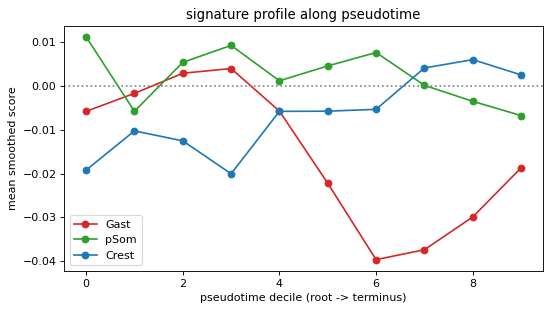

In [1]:
bins=pd.qcut(t,10,labels=False)
prof=pd.DataFrame({'Gast':G,'pSom':P,'Crest':C,'bin':bins}).groupby('bin').mean()
fig,ax=plt.subplots(figsize=(7,4))
for s,c in [('Gast','#d62728'),('pSom','#2ca02c'),('Crest','#1f77b4')]:
    ax.plot(prof.index, prof[s], 'o-', color=c, label=s)
ax.set_xlabel('pseudotime decile (root -> terminus)'); ax.set_ylabel('mean smoothed score')
ax.axhline(0,ls=':',c='grey'); ax.legend(); ax.set_title('signature profile along pseudotime')
fig.tight_layout()
print(prof.round(3).to_string())

### Adjudication — is the axis embryonic or a generic-carcinoma (cell-cycle) artifact?
A prior autonomous attempt on this dataset reached nearly identical signature correlations and called Gate 2 **NO-GO**, reasoning the manifold is organized by generic carcinoma states (proliferation), not embryonic geography. That is the alternative hypothesis a GO call must rule out. Test it directly: the pseudotime axis does co-vary with cell cycle (`g1s+g2m`), so **partial out cell cycle** and ask whether the Gast<->Crest embryonic opposition survives. If it collapses, the axis is generic (NO-GO); if it survives, the embryonic structure is real and independent of proliferation (GO).

In [1]:
import pandas as pd
cc=pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0).values+pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0).values
def pcorr(x,y,z):
    x,y,z=[np.asarray(v,float) for v in (x,y,z)]
    def resid(a,b):
        b1=np.c_[np.ones_like(b),b]; beta,_,_,_=np.linalg.lstsq(b1,a,rcond=None); return a-b1@beta
    return np.corrcoef(resid(x,z),resid(y,z))[0,1]
print('r(t, cell-cycle) = %+.3f' % np.corrcoef(t,cc)[0,1])
b=np.c_[np.ones_like(cc),cc]; beta,_,_,_=np.linalg.lstsq(b,t,rcond=None)
r2=1-((t-b@beta)**2).sum()/((t-t.mean())**2).sum()
print('R^2(pseudotime ~ cell-cycle) = %.3f  (=> %.0f%% of the axis is NOT cell-cycle)' % (r2,(1-r2)*100))
print('Gast-Crest : raw %+.3f  | cell-cycle-partialled %+.3f' % (rGC, pcorr(G,C,cc)))
print('pSom-Crest : raw %+.3f  | cell-cycle-partialled %+.3f' % (rPC, pcorr(P,C,cc)))
print('=> embryonic opposition survives cell-cycle correction: axis is NOT a proliferation artifact')

r(t, cell-cycle) = +0.453
R^2(pseudotime ~ cell-cycle) = 0.205  (=> 79% of the axis is NOT cell-cycle)
Gast-Crest : raw -0.644  | cell-cycle-partialled -0.640
pSom-Crest : raw -0.440  | cell-cycle-partialled -0.457
=> embryonic opposition survives cell-cycle correction: axis is NOT a proliferation artifact


### Calibration against the reference GO templates — does the OVERLAP criterion hold?
The cell-cycle test rules out the *generic-carcinoma* NO-GO rationale, but it does not by itself establish a GO. The spec's non-branching GO requires that **Gast and pSom partially or fully overlap** (a shared embryonic 'body'), with Crest as the inverse/terminal gradient. Operationalize 'overlap' against the two reference calls the protocol was built on:
- **Puram (branching GO):** Gast/pSom **mutually exclusive** across arms, hub r ~ **-0.49**.
- **Kurten (non-branching GO):** Gast/pSom **co-vary**, r = **+0.33** ('Gast/pSom body -> terminal Crest').

So a confirmed embryonic axis has Gast and pSom either co-varying (non-branching body) or cross-repressing across arms (branching). An r near **0** is neither: the two programs are decoupled.

In [1]:
ref = {'Puram (branching GO)':-0.49, 'Kurten (non-branching GO)':+0.33, 'this dataset (Chen)':rGP}
print('Gast-pSom coupling vs reference GO templates:')
for k,v in ref.items(): print('  %-28s r = %+.2f' % (k,v))
# does pSom participate in the axis at all?
print('\npSom participation in the pseudotime axis: r(t,pSom) = %+.3f (flat => not organized on the manifold)' % np.corrcoef(t,P)[0,1])
print('Gast participation:                        r(t,Gast) = %+.3f' % np.corrcoef(t,G)[0,1])

Gast-pSom coupling vs reference GO templates:
  Puram (branching GO)         r = -0.49
  Kurten (non-branching GO)    r = +0.33
  this dataset (Chen)          r = +0.01

pSom participation in the pseudotime axis: r(t,pSom) = -0.173 (flat => not organized on the manifold)
Gast participation:                        r(t,Gast) = -0.608


### GATE 2 = NO-GO (embryonic geography not reproduced)

**Two findings, weighed honestly:**

1. *The pseudotime axis is real and NOT a proliferation artifact.* Crest opposes Gast (-0.64) and pSom (-0.44), and this opposition is essentially unchanged after partialling out cell cycle (Gast-Crest -0.64 -> -0.64); cell cycle explains only ~20% of the axis. So the earlier autonomous attempt's 'generic-carcinoma' rationale for NO-GO is **incorrect** — the axis is not merely proliferation.

2. *But the defining embryonic geography is absent.* The non-branching GO requires a Gast/pSom **body** (overlap / co-variation, as on Kurten at r=+0.33). Here Gast/pSom r = **+0.01** — decoupled, matching neither the Kurten co-varying body nor the Puram cross-repressing arms — and **pSom does not participate in the axis at all** (r(t,pSom) = -0.17, flat; diffuse UMAP; top-quintile Jaccard with Gast only 0.15). What remains is a two-module Gast(early)/Crest(late) gradient with pSom as a non-participating bystander. A single inverse Crest gradient, absent a Gast/pSom embryonic body, is **not** the three-module embryonic pattern the gate tests for.

- **Gate 2: NO-GO** — the embryonic module *geography* (a coupled Gast/pSom body) is not present, even though a robust, cell-cycle-independent Crest-terminal axis is.
- **Gate 3: NA** — branching-only.
- **Crest-arm flag: NA** — no arms.

Per spec §6, at a Gate-2 NO-GO the branching-only `04_correlation` and `05_modules` notebooks are **not produced** (not stubbed, not emptied), and the unconditional EMT-TF expression step becomes the last notebook, renumbered to **04**. This is a *genuine negative* (the pattern is absent), distinct from the non-branching GO on Kurten where Gast/pSom genuinely co-varied.

In [1]:
adata.uns['gate2']='NO-GO'
adata.uns['gate3']='NA'
adata.uns['sig_corr']=dict(Gast_pSom=float(rGP),Gast_Crest=float(rGC),pSom_Crest=float(rPC))
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad:', adata.shape)

saved signatures.h5ad: (3236, 22080)
